Training LP and EP

Import packages and connect Drive

In [ ]:
from google.colab import drive
from pathlib import Path
import json, os, random
import numpy as np
import pandas as pd
import tensorflow as tf

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Set the Drive paths

In [ ]:
PROJECT_DIR = Path('/content/drive/MyDrive/Research/Model_Training')
IMAGE_DIR = PROJECT_DIR / 'Images'
MANIFEST_DIR = PROJECT_DIR / 'private_manifests' / 'components'

assert PROJECT_DIR.exists(), f'Project folder not found: {PROJECT_DIR}'
assert IMAGE_DIR.exists(), f'Image folder not found: {IMAGE_DIR}'
assert MANIFEST_DIR.exists(), f'Manifest folder not found: {MANIFEST_DIR}'

In [ ]:
# This selects the combined three-class task, generated manifest and ResNet50 backbone.
TASK = 'leukoplakia_erythroplakia_3class'
TASK_MODE = 'multiclass'
NUM_CLASSES = 3
CLASS_NAMES = ['neither_target', 'leukoplakia', 'erythroplakia']
MODEL_NAME = 'ResNet50'
APP = tf.keras.applications.ResNet50
PREPROCESS = tf.keras.applications.resnet50.preprocess_input
CSV_PATH = MANIFEST_DIR / 'leukoplakia_erythroplakia_3class.csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'leukoplakia_erythroplakia_3class_ResNet50'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert CSV_PATH.is_file(), f'Manifest not found: {CSV_PATH}'

Set the shared training defaults

In [ ]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 16
EPOCHS_FROZEN = 15
EPOCHS_FINE_TUNE = 8
SEED = 42
USE_CLASS_WEIGHTS = True
USE_HORIZONTAL_FLIP = False

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Images:', IMAGE_DIR)
print('Manifest folder:', MANIFEST_DIR)

Images: /content/drive/MyDrive/Research/Model_Training/Images
Manifest folder: /content/drive/MyDrive/Research/Model_Training/private_manifests/components


Read CSV and check the split

In [ ]:
# This loads the supplied patient-level split so each patient stays in the assigned group.
df = pd.read_csv(CSV_PATH)
required = {'image_id', 'patient_id', 'target', 'split'}
missing = required - set(df.columns)
assert not missing, f'Missing columns: {missing}'

df['target'] = df['target'].astype(int)
expected_targets = set(range(NUM_CLASSES))
assert set(df['target'].unique()).issubset(expected_targets), f'target values must be within {expected_targets}'
assert set(df['split'].unique()).issubset({'train', 'validation', 'test'})

split_per_patient = df.groupby('patient_id')['split'].nunique()
leaking_patients = split_per_patient[split_per_patient > 1]
assert len(leaking_patients) == 0, f'Patient leakage found: {list(leaking_patients.index)}'

print('Rows:', len(df))
print('Patients:', df['patient_id'].nunique())
for split_name in ['train', 'validation', 'test']:
    part = df[df['split'] == split_name]
    print(f'{split_name}: {len(part)} images / {part["patient_id"].nunique()} patients')
    for class_id, class_name in enumerate(CLASS_NAMES):
        class_rows = part[part['target'] == class_id]
        print(f'  {class_id} {class_name}: {len(class_rows)} images / '
              f'{class_rows["patient_id"].nunique()} patients')

assert (df['split'] == 'train').any(), 'No training rows'
assert (df['split'] == 'validation').any(), 'No validation rows'
assert (df['split'] == 'test').any(), 'No test rows'
assert df[df['split'] == 'train']['target'].nunique() == NUM_CLASSES, 'Training split must contain every configured class'

Rows: 2992
Patients: 711
train: 2074 images / 499 patients
  0 neither_target: 1983 images / 487 patients
  1 leukoplakia: 77 images / 47 patients
  2 erythroplakia: 14 images / 8 patients
validation: 449 images / 107 patients
  0 neither_target: 406 images / 96 patients
  1 leukoplakia: 39 images / 16 patients
  2 erythroplakia: 4 images / 3 patients
test: 469 images / 105 patients
  0 neither_target: 445 images / 100 patients
  1 leukoplakia: 20 images / 10 patients
  2 erythroplakia: 4 images / 1 patients


Match CSV image IDs to files and build datasets

In [ ]:
from collections import defaultdict

allowed_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
by_name, by_stem = defaultdict(list), defaultdict(list)
for path in IMAGE_DIR.rglob('*'):
    if path.is_file() and path.suffix.lower() in allowed_ext:
        by_name[path.name.casefold()].append(path)
        by_stem[path.stem.casefold()].append(path)

def resolve_image(image_id):
    key = Path(str(image_id)).name.casefold()
    matches = by_name.get(key, [])
    if not matches:
        matches = by_stem.get(Path(key).stem.casefold(), [])
    # This catches image names that map to more than one file extension.
    matches = sorted(set(matches))
    if len(matches) != 1:
        return None, [str(p) for p in matches]
    return str(matches[0]), []

resolved, missing, ambiguous = [], [], []
for image_id in df['image_id']:
    path, choices = resolve_image(image_id)
    resolved.append(path)
    if path is None:
        if choices:
            ambiguous.append((image_id, choices))
        else:
            missing.append(image_id)

if missing or ambiguous:
    print('Missing image IDs (first 20):', missing[:20])
    print('Ambiguous image IDs (first 10):', ambiguous[:10])
    raise ValueError('Fix image paths/names before training; no rows were dropped.')

df['image_path'] = resolved
print(f'Matched {len(df)} manifest rows to image files.')

train_df = df[df['split'] == 'train'].copy()
val_df = df[df['split'] == 'validation'].copy()
test_df = df[df['split'] == 'test'].copy()

AUTOTUNE = tf.data.AUTOTUNE
augment_layers = [
    tf.keras.layers.RandomRotation(0.03, fill_mode='reflect'),
    tf.keras.layers.RandomTranslation(0.02, 0.02, fill_mode='reflect'),
    tf.keras.layers.RandomZoom(0.05, fill_mode='reflect'),
    tf.keras.layers.RandomContrast(0.10),
]
if USE_HORIZONTAL_FLIP:
    augment_layers.insert(0, tf.keras.layers.RandomFlip('horizontal'))
augmentation = tf.keras.Sequential(augment_layers, name='train_only_augmentation')

def make_dataset(frame, training=False):
    paths = frame['image_path'].astype(str).to_numpy()
    labels = frame['target'].astype('int32' if TASK_MODE == 'multiclass' else 'float32').to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)

    def load_and_prepare(path, label):
        raw = tf.io.read_file(path)
        image = tf.io.decode_image(raw, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.cast(image, tf.float32)
        # This preserves the full image and pads it to a square before resizing.
        image = tf.image.resize_with_pad(image, IMG_HEIGHT, IMG_WIDTH)
        if training:
            # These transformations add training variety while validation and test images stay unchanged.
            image = augmentation(image, training=True)
            image = tf.clip_by_value(image, 0.0, 255.0)
        image = PREPROCESS(image)
        return image, label

    return ds.map(load_and_prepare, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)
print('Datasets ready:', len(train_df), len(val_df), len(test_df))

Matched 2992 manifest rows to image files.
Datasets ready: 2074 449 469


Build the pretrained classifier

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# This builds the single pretrained architecture selected in the member configuration.
base_model = APP(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name='preprocessed_image')
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
if TASK_MODE == 'multiclass':
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
else:
    outputs = layers.Dense(1, activation='sigmoid', name='disease_probability')(x)
model = keras.Model(inputs, outputs, name=f'{TASK}_{MODEL_NAME}')

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=(keras.losses.SparseCategoricalCrossentropy()
              if TASK_MODE == 'multiclass' else keras.losses.BinaryCrossentropy()),
        metrics=([
            keras.metrics.SparseCategoricalAccuracy(name='accuracy'),
        ] if TASK_MODE == 'multiclass' else [
            keras.metrics.BinaryAccuracy(name='accuracy', threshold=0.5),
            keras.metrics.Precision(name='precision', thresholds=0.5),
            keras.metrics.Recall(name='recall', thresholds=0.5),
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.AUC(name='pr_auc', curve='PR'),
        ]),
    )

compile_model(model, learning_rate=1e-3)
model.summary()

# These weights address training class imbalance; validation and test keep their original class proportions.
counts = np.bincount(train_df['target'].astype(int), minlength=NUM_CLASSES)
assert np.all(counts > 0), f'Every configured class must occur in training: {counts}'
class_weight = {i: len(train_df) / (NUM_CLASSES * counts[i]) for i in range(NUM_CLASSES)}
print('Training class counts by class ID:', counts)
print('Class weights:', class_weight if USE_CLASS_WEIGHTS else 'disabled')

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "leukoplakia_erythroplakia_3class_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ preprocessed_image (InputLayer) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 6,147 (24.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Training class counts by class ID: [1983   77   14]
Class weights: {0: np.float64(0.34863002185241215), 1: np.float64(8.978354978354979), 2: np.float64(49.38095238095238)}


Training

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger

frozen_path = OUTPUT_DIR / 'best_frozen_model.keras'
common_callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
    CSVLogger(str(OUTPUT_DIR / 'frozen_training_history.csv')),
    ModelCheckpoint(str(frozen_path), monitor='val_loss', save_best_only=True),
]

history_frozen = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FROZEN,
    class_weight=class_weight if USE_CLASS_WEIGHTS else None,
    callbacks=common_callbacks,
)
model_frozen = keras.models.load_model(frozen_path)
val_loss_frozen = model_frozen.evaluate(val_ds, verbose=0)[0]
print('Best frozen validation loss:', val_loss_frozen)

Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1044s 8s/step - accuracy: 0.4204 - loss: 1.5650 - val_accuracy: 0.8396 - val_loss: 0.5392 - learning_rate: 0.0010
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1016s 8s/step - accuracy: 0.5598 - loss: 1.0606 - val_accuracy: 0.7439 - val_loss: 0.5791 - learning_rate: 0.0010
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1015s 8s/step - accuracy: 0.6543 - loss: 0.7123 - val_accuracy: 0.7372 - val_loss: 0.5755 - learning_rate: 0.0010
Epoch 4/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1000s 8s/step - accuracy: 0.7054 - loss: 0.5460 - val_accuracy: 0.8085 - val_loss: 0.4715 - learning_rate: 3.0000e-04
Epoch 5/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1050s 8s/step - accuracy: 0.7454 - loss: 0.5648 - val_accuracy: 0.6236 - val_loss: 0.9086 - learning_rate: 3.0000e-04
Epoch 6/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1001s 8s/step - accuracy: 0.7252 - loss: 0.5583 - val_accuracy: 0.8107 - val_loss: 0.4845 - learning_rate: 3.0000e-04
Epoch 7/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1040s 8s/step - accuracy

Fine Tuning Cell

In [ ]:
frozen_path = OUTPUT_DIR / "best_frozen_model.keras"
print("Checkpoint:", frozen_path)
print("Exists:", frozen_path.exists())

Checkpoint: /content/drive/MyDrive/Research/Model_Training/outputs/leukoplakia_erythroplakia_3class_ResNet50/best_frozen_model.keras
Exists: True


In [ ]:
# Load the best saved frozen model
model = keras.models.load_model(frozen_path)

# Unfreeze only the last ResNet50 layers; keep BatchNorm layers frozen
base_model = model.get_layer("resnet50")
base_model.trainable = True

unfreeze_last = 30
cutoff = max(0, len(base_model.layers) - unfreeze_last)

for layer in base_model.layers[:cutoff]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a low learning rate for fine-tuning
compile_model(model, learning_rate=1e-5)

finetuned_path = OUTPUT_DIR / "best_finetuned_model.keras"

finetune_callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(finetuned_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
    keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "finetune_training_history.csv")
    ),
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNE,
    class_weight=class_weight if USE_CLASS_WEIGHTS else None,
    callbacks=finetune_callbacks,
    verbose=1,
)

print("Best fine-tuned model saved to:", finetuned_path)

Epoch 1/8
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6981 - loss: 0.7824
Epoch 1: val_loss improved from None to 0.53787, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/leukoplakia_erythroplakia_3class_ResNet50/best_finetuned_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/leukoplakia_erythroplakia_3class_ResNet50/best_finetuned_model.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 616s 5s/step - accuracy: 0.7015 - loss: 0.6293 - val_accuracy: 0.7773 - val_loss: 0.5379 - learning_rate: 1.0000e-05
Epoch 2/8
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7793 - loss: 0.3864
Epoch 2: val_loss improved from 0.53787 to 0.51121, saving model to /content/drive/MyDrive/Research/Model_Training/outputs/leukoplakia_erythroplakia_3class_ResNet50/best_finetuned_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Research/Model_Training/outputs/leukoplakia_erythroplakia_3class_ResNet50/best_finetuned

Save validation curves

Files in output folder:
best_finetuned_model.keras
best_frozen_model.keras
finetune_training_history.csv
frozen_training_history.csv
validation_curves.png


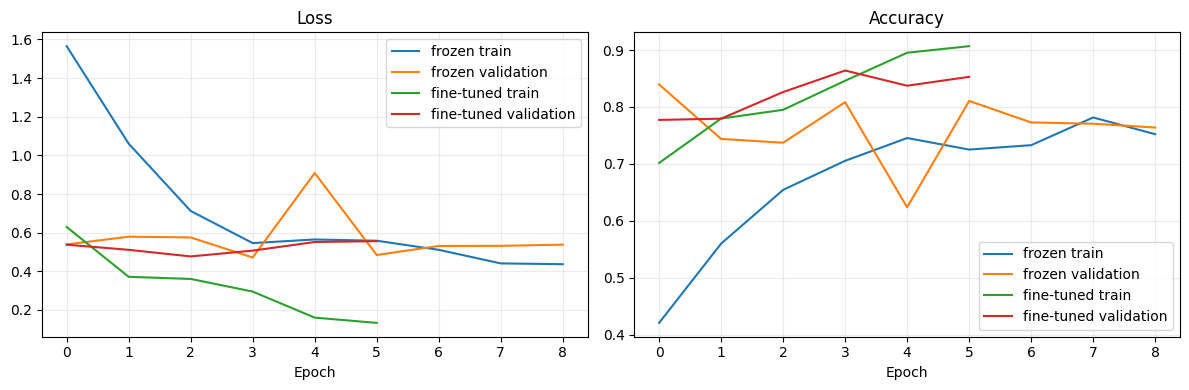

Saved: /content/drive/MyDrive/Research/Model_Training/outputs/leukoplakia_erythroplakia_3class_ResNet50/validation_curves.png


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Match this to the OUTPUT_DIR used in your notebook.
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Research/Model_Training/outputs/"
    "leukoplakia_erythroplakia_3class_ResNet50"
)

# Check which training logs were saved.
print("Files in output folder:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(path.name)

log_options = [
    ("frozen", OUTPUT_DIR / "frozen_training_history.csv"),
    ("fine-tuned", OUTPUT_DIR / "finetune_training_history.csv"),
    ("fine-tuned", OUTPUT_DIR / "fine_tune_training_history.csv"),
]

histories = []
for stage, path in log_options:
    if path.exists():
        histories.append((stage, pd.read_csv(path)))

if not histories:
    raise FileNotFoundError(
        "No training-history CSVs found. Check OUTPUT_DIR and the filenames "
        "printed above. The model checkpoints may still be saved."
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for stage, df in histories:
    if "loss" in df:
        axes[0].plot(df["loss"], label=f"{stage} train")
    if "val_loss" in df:
        axes[0].plot(df["val_loss"], label=f"{stage} validation")
    if "accuracy" in df:
        axes[1].plot(df["accuracy"], label=f"{stage} train")
    if "val_accuracy" in df:
        axes[1].plot(df["val_accuracy"], label=f"{stage} validation")

axes[0].set_title("Loss")
axes[1].set_title("Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True, alpha=0.25)

fig.tight_layout()
curve_path = OUTPUT_DIR / "validation_curves.png"
fig.savefig(curve_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", curve_path)

Save the experiment configuration and README

In [ ]:
import json
import pandas as pd

# Count epochs from the in-memory history if available,
# otherwise read the saved CSV log.
def completed_epochs(history_name, csv_name):
    history = globals().get(history_name)
    if history is not None:
        return len(history.history.get("loss", []))

    csv_path = OUTPUT_DIR / csv_name
    if csv_path.exists():
        return len(pd.read_csv(csv_path))

    return 0

# Reuse final_path if it still exists in this runtime.
# Otherwise, prefer the fine-tuned checkpoint if it was saved.
if "final_path" not in globals():
    candidates = [
        ("fine-tuned", OUTPUT_DIR / "best_finetuned_model.keras"),
        ("fine-tuned", OUTPUT_DIR / "best_finetuned.keras"),
        ("frozen", OUTPUT_DIR / "best_frozen_model.keras"),
        ("frozen", OUTPUT_DIR / "best_frozen.keras"),
    ]
    found = [(stage, path) for stage, path in candidates if path.exists()]
    if not found:
        raise FileNotFoundError(f"No model checkpoint found in {OUTPUT_DIR}")
    selected_stage, final_path = found[0]
elif "selected_stage" not in globals():
    selected_stage = "fine-tuned" if "finetun" in final_path.name.lower() else "frozen"

# Summarize the splits. These dataframes must be recreated by the data-loading cell.
split_summary = {}
for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    positive = frame[frame["target"] == 1]
    split_summary[split_name] = {
        "images": int(len(frame)),
        "patients": int(frame["patient_id"].nunique()),
        "positive_images": int(len(positive)),
        "positive_patients": int(positive["patient_id"].nunique()),
    }

experiment_config = {
    "task": TASK,
    "task_mode": TASK_MODE,
    "class_names": CLASS_NAMES,
    "architecture": MODEL_NAME,
    "pretrained_weights": "ImageNet",
    "selected_stage": selected_stage,
    "selected_checkpoint": final_path.name,
    "input": {
        "color": "RGB",
        "height": IMG_HEIGHT,
        "width": IMG_WIDTH,
        "resize": "tf.image.resize_with_pad",
        "model_preprocessing": getattr(PREPROCESS, "__name__", str(PREPROCESS)),
    },
    "augmentation": {
        "rotation_factor": 0.03,
        "translation_height_width": [0.02, 0.02],
        "zoom_factor": 0.05,
        "contrast_factor": 0.10,
        "horizontal_flip": USE_HORIZONTAL_FLIP,
        "training_only": True,
    },
    "class_weights_enabled": USE_CLASS_WEIGHTS,
    "optimizer": "Adam",
    "frozen_learning_rate": 1e-3,
    "fine_tune_learning_rate": 1e-5,
    "frozen_epochs_requested": EPOCHS_FROZEN,
    "frozen_epochs_completed": completed_epochs(
        "history_frozen", "frozen_training_history.csv"
    ),
    "fine_tune_epochs_requested": EPOCHS_FINE_TUNE,
    "fine_tune_epochs_completed": completed_epochs(
        "history_fine", "finetune_training_history.csv"
    ),
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "split_counts": split_summary,
}

with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

with open(OUTPUT_DIR / "dataset_split_summary.json", "w") as f:
    json.dump(split_summary, f, indent=2)

readme = f"""# {TASK} model run

- Architecture: {MODEL_NAME} with ImageNet pretrained weights
- Task mode: {TASK_MODE}; classes: {CLASS_NAMES}
- Selected stage: {selected_stage}
- Saved model: `{final_path.name}`
- Input: RGB, {IMG_HEIGHT}x{IMG_WIDTH}; resized with padding
- Model preprocessing: `{getattr(PREPROCESS, "__name__", str(PREPROCESS))}`
- Class weights enabled: {USE_CLASS_WEIGHTS}
- Batch size: {BATCH_SIZE}; seed: {SEED}

See `experiment_config.json` and `dataset_split_summary.json` for run settings and split counts.
Training-history CSV files and `validation_curves.png` contain the training history, if saved.
"""

(OUTPUT_DIR / "README.md").write_text(readme)
print("Saved configuration, split summary, and README in:", OUTPUT_DIR)

Saved configuration, split summary, and README in: /content/drive/MyDrive/Research/Model_Training/outputs/leukoplakia_erythroplakia_3class_ResNet50
